In [15]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
from astropy.io import fits
import os

In [17]:
exp_files0=os.listdir('../../data/spectra/EXPRES_newformat/')
exp_files=[f for f in exp_files0 if f.endswith('.fits')]

In [18]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    f.info()

Filename: ../../data/spectra/EXPRES_newformat/expresL1_202412015165.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      65   ()      
  1  optimal       1 BinTableHDU     91   86R x 17C   [7920D, 7920D, 7920D, 7920D, 7920D, 7920I, 7920L, 7920D, I, 7920D, 7920D, 7920L, 7920D, 7920D, 7920D, 7920D, 7920L]   
  2  EXPOSURE METER + BARY_CORR    1 BinTableHDU     79   146R x 5C   [512D, D, 512D, 512L, D]   


In [22]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    head=f[0].header
head

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
SITELONG= '-111.422515'        / East longitude site, decimal degrees           
SITELAT = '34.744305'          / Latitude of site, decimal degrees              
SITEELEV= '2337.0  '           / Elevation of observatory site (meters)         
TELESCP = 'DCT     '           / Name of telescope                              
INSTRMNT= 'EXPRES  '           / Name of instrument                             
DETECTOR= 'STA1600 '           / Detector type                                  
FPA     = 'EXPRES-D0'          / Focal Plane Array Identifier                   
CNTRTYPE= 'STA-Archon'         / Detector Controller                            
CNTRVRS = '1       '        

In [23]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    head=f[1].header
head

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =               799922 / length of dimension 1                          
NAXIS2  =                   86 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   17 / number of table fields                         
VERSION = '0.4.2   '           / EXPRES Pipeline code version                   
EXTNAME = 'optimal '           / Extraction algorithm                           
DATE-EXT= '2024-12-02T05:18:51.836' / Date and time of extraction               
SCATLGHT=                    T / Scattered light removed before extraction      
EXT_SIZE=                   

In [24]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    head=f[2].header
head

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 8720 / length of dimension 1                          
NAXIS2  =                  146 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    5 / number of table fields                         
VERSION = '0.4.2   '           / EXPRES Pipeline code version                   
EXTNAME = 'EXPOSURE METER + BARY_CORR' / extension name                         
EXTVER  =                    1 / extension value                                
CAL_DATE=            3242018.0 / Date the wavelength calibration image was taken
CAL_SLOP=       0.5288562362

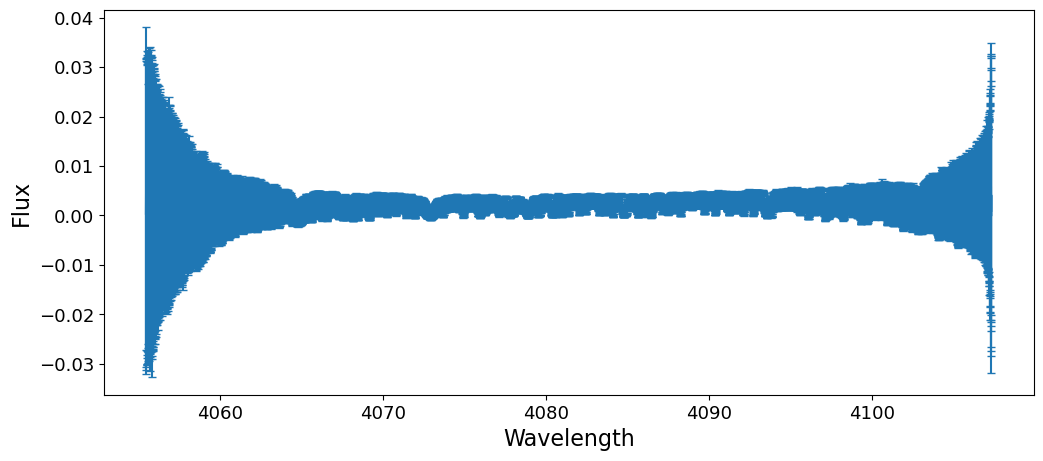

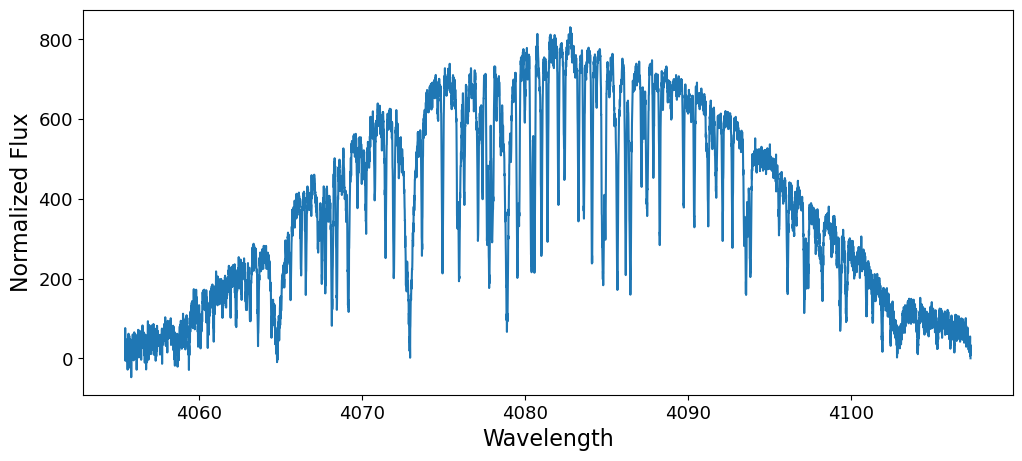

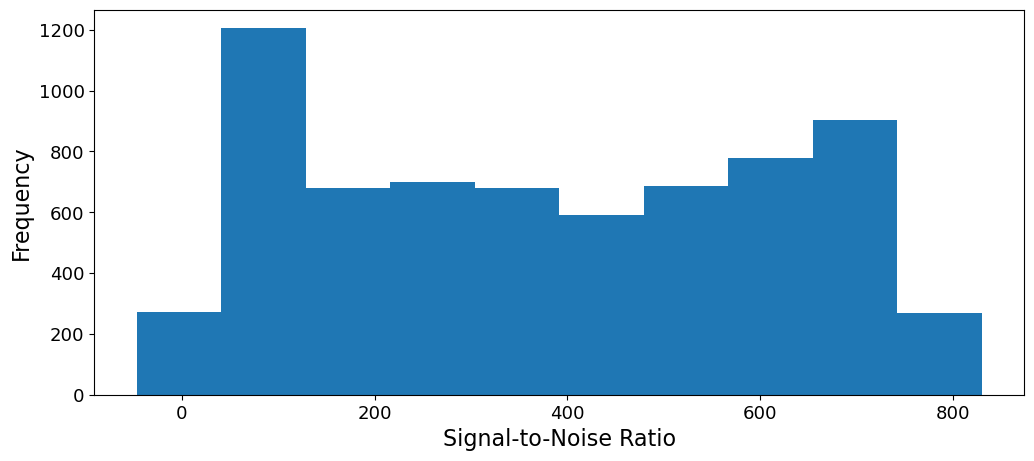

In [34]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    data=f[1].data
plt.errorbar(data['wavelength'][10,:], data['spectrum'][10,:]*data['continuum'][10,:], yerr=data['uncertainty'][10,:])
plt.xlabel('Wavelength')
plt.ylabel('Flux')
s=data['spectrum'][10,:]/data['continuum'][10,:]
e=data['uncertainty'][10,:]
plt.figure()
plt.errorbar(data['wavelength'][10,:], s/e)
plt.xlabel('Wavelength')
plt.ylabel('Normalized Flux')
plt.show()


plt.figure()
plt.hist(s/e)
plt.xlabel('Signal-to-Noise Ratio')
plt.ylabel('Frequency')
plt.show()

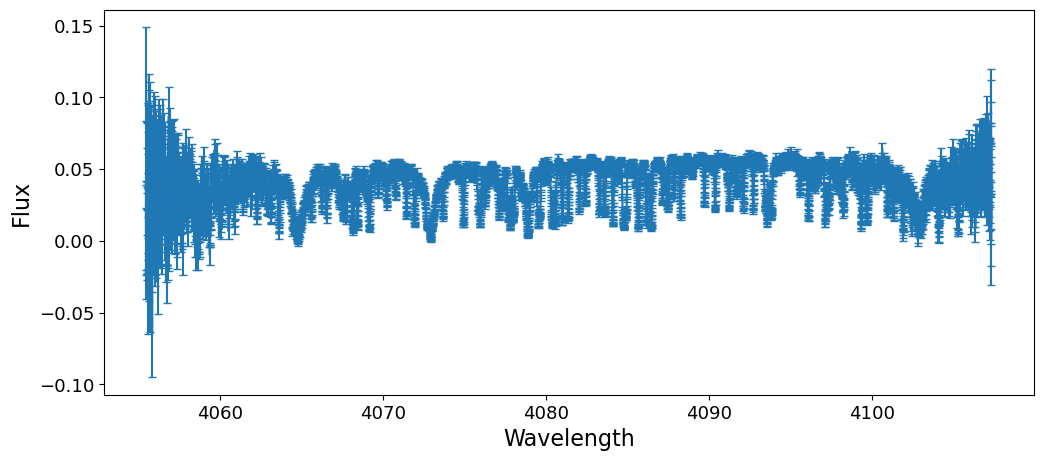

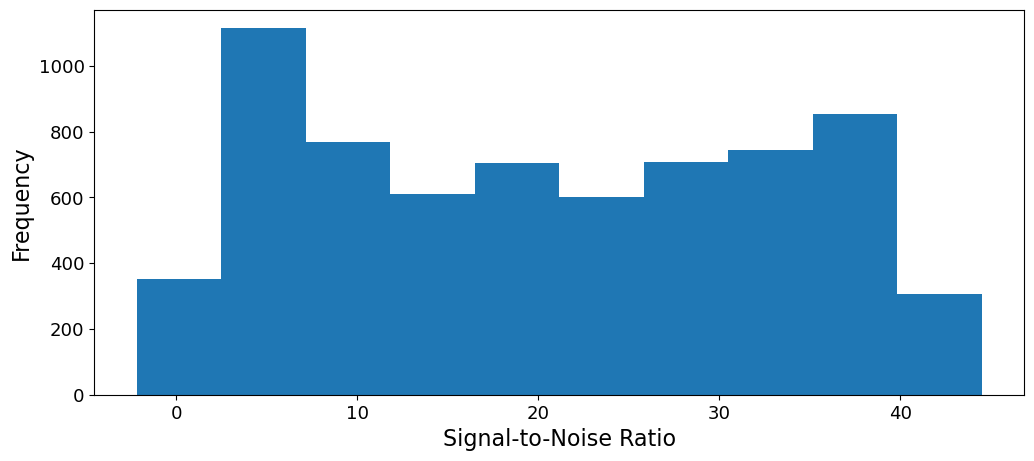

In [ ]:
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    data=f[2].data
plt.errorbar(data['wavelength'][10,:], data['spectrum'][10,:], yerr=data['uncertainty'][10,:])
plt.xlabel('Wavelength')
plt.ylabel('Flux')
s=data['spectrum'][10,:]
e=data['uncertainty'][10,:]
plt.figure()
plt.hist(s/e)
plt.xlabel('Signal-to-Noise Ratio')
plt.ylabel('Frequency')
plt.show()

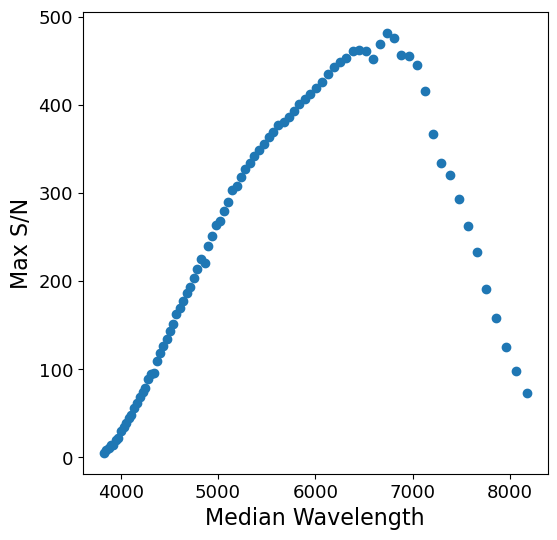

In [43]:
#for each order, calculate the max S/N for that order, also calculate the median wavelength, then plot S/N vs wavelength
orders_max_s2n = []
orders_median_wl = []
with fits.open('../../data/spectra/EXPRES_newformat/'+exp_files[0]) as f:
    data=f[1].data
    #data.keys()
    w=data['wavelength']
    s=data['spectrum']
    e=data['uncertainty']
    for j in range(s.shape[0]):
        order_s2n = s[j]/e[j]
        orders_max_s2n.append(np.nanmax(order_s2n))
        orders_median_wl.append(np.nanmedian(w[j]))
plt.figure(figsize=(6,6))
plt.scatter(orders_median_wl, orders_max_s2n)
plt.xlabel('Median Wavelength')
plt.ylabel('Max S/N')
plt.show()